# Esercizi da soli · Le variabili dummy

*Metodi Matematici e Statistici per le Decisioni Economiche · A.A. 2026/27 · Esercitazione 2*

**Versione svolta**, con il codice e i commenti per leggere i risultati. Prima prova da solo con `esercitazione2_da_soli.ipynb`, senza soluzioni.

Un'azienda vende ai suoi clienti in tre modi: dall'app, dal sito e in un negozio fisico. Il responsabile vendite deve decidere su quale canale investire, e vuole capire se i clienti dei tre canali spendono in modo diverso. `clienti.csv` (lo stesso dell'esercitazione 1) descrive 200 clienti: `canale` (`App`, `Negozio` o `Sito`), `spesa_annua` (in euro), `ordini` (numero di ordini nell'anno), `eta`.

Gli esercizi seguono gli stessi passi di quelli fatti insieme sui seggiolini auto. **Prima di scrivere codice, leggi la domanda** e completa la riga **Cosa mi chiede?**:
- la **y**: cosa vogliamo spiegare o prevedere;
- la **x**: con cosa la spieghiamo;
- il **comando**: una media, un grafico, un modello (`smf.ols`), una previsione (`predict`).

> **Per salvare il tuo lavoro scarica il notebook:** File → Scarica → Scarica .ipynb. Il file scaricato è tuo: per riaprirlo, su Colab File → Carica notebook, e da lì Salva funziona normalmente. Se hai aperto il notebook dal sito con *Apri in Colab*, non usare Salva: Colab proverebbe a salvarlo su GitHub.

In [1]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf

In [2]:
clienti = pl.read_csv("https://www.vincnardelli.com/msd/dati/clienti.csv")
clienti.head()

cliente,canale,spesa_annua,ordini,eta
str,str,i64,i64,i64
"""C001""","""App""",136,2,26
"""C002""","""Negozio""",232,3,41
"""C003""","""Sito""",203,3,38
"""C004""","""App""",43,1,18
"""C005""","""Sito""",123,4,40


### 2.1 I clienti che comprano in negozio spendono di più di quelli che comprano dall'app? Calcola la spesa media dei due gruppi e fai un boxplot della spesa per canale.

**Cosa mi chiede?** "Spendono di più": y = `spesa_annua`. "In negozio, dall'app": x = `canale`. Comando: due medie, con `filter` e `mean`, e un boxplot.

In [3]:
# spesa media dall'app: 125 euro
clienti.filter(pl.col("canale") == "App").select(pl.col("spesa_annua").mean())

spesa_annua
f64
125.408451


In [4]:
# spesa media in negozio: 250 euro
clienti.filter(pl.col("canale") == "Negozio").select(pl.col("spesa_annua").mean())

spesa_annua
f64
249.534884


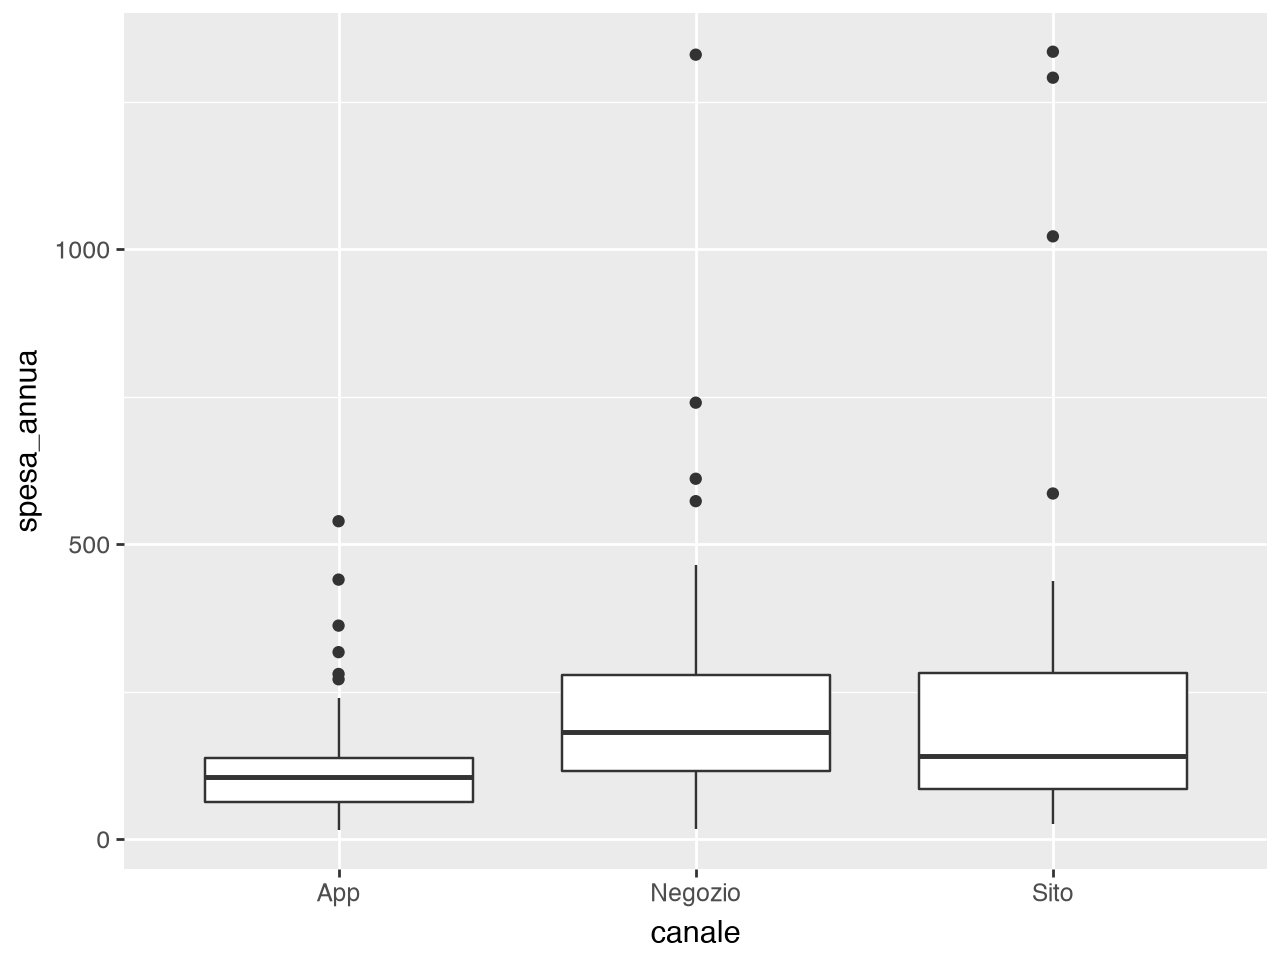

In [5]:
ggplot(clienti, aes(x="canale", y="spesa_annua")) + geom_boxplot()

### 2.2 Stima un modello per la spesa annua in funzione del canale. Qual è la categoria di riferimento? Come leggi intercetta e coefficienti? Sono significativi?

**Cosa mi chiede?** "La spesa annua in funzione del canale": y = `spesa_annua`, x = `canale`. Comando: `smf.ols`. `canale` è testo con tre categorie: statsmodels crea due dummy.

In [6]:
# categoria di riferimento: App (la prima in ordine alfabetico); intercetta 125: la spesa media dall'app
# canale[T.Negozio] 124: in negozio, in media 124 euro in più che dall'app; p-value 0.001 <= 0.05, significativa
# canale[T.Sito] 82: dal sito, in media 82 euro in più che dall'app; p-value 0.008 <= 0.05, significativa
# R² 0.06: il modello spiega il 6% della variabilità della spesa
modello1 = smf.ols("spesa_annua ~ canale", data=clienti).fit()
modello1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            spesa_annua   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                  0.052
Method:                 Least Squares   F-statistic:                     6.446
Date:                Wed, 18 Nov 2026   Prob (F-statistic):            0.00194
Time:                        22:37:45   Log-Likelihood:                -1333.6
No. Observations:                 200   AIC:                             2673.
Df Residuals:                     197   BIC:                             2683.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           125.4085     22.765      5.509      0.000      80.514     170.303
canale[T.Negozio]   124.1264     37.067      3.349      0.001      51.027     197.226
canale[T.Sito]       82.3241     30.759      2.676      0.008      21.665     142.983
==============================================================================
Omnibus:                      177.222   Durbin-Watson:                   2.060
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2531.251
Skew:                           3.463   Prob(JB):                         0.00
Kurtosis:                      18.993   Cond. No.                         3.76
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### 2.3 Che relazione c'è tra il numero di ordini e la spesa annua? Fai un grafico a dispersione per ogni canale, uno alla volta, poi uno con tutti i clienti colorati per canale.

**Cosa mi chiede?** "Relazione tra ordini e spesa": x = `ordini`, y = `spesa_annua`. Comando: `ggplot` con `geom_point`; "per ogni canale": `filter` dentro `ggplot`; "colorati per canale": `color="canale"` dentro `aes`.

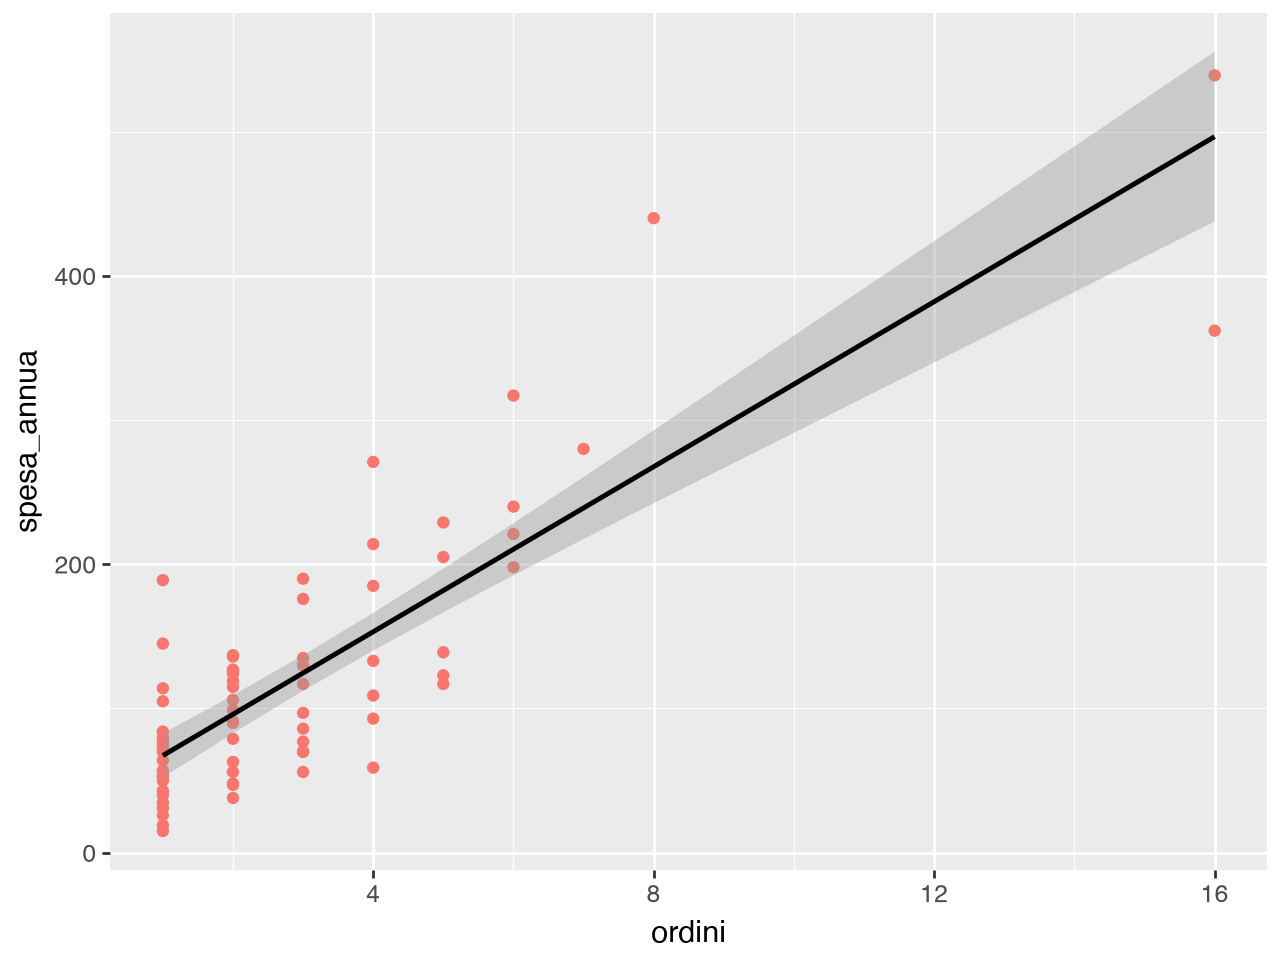

In [7]:
# solo i clienti dell'app: più ordini, più spesa
ggplot(clienti.filter(pl.col("canale") == "App"), aes(x="ordini", y="spesa_annua")) + geom_point(color="#F8766D") + geom_smooth(method="lm")

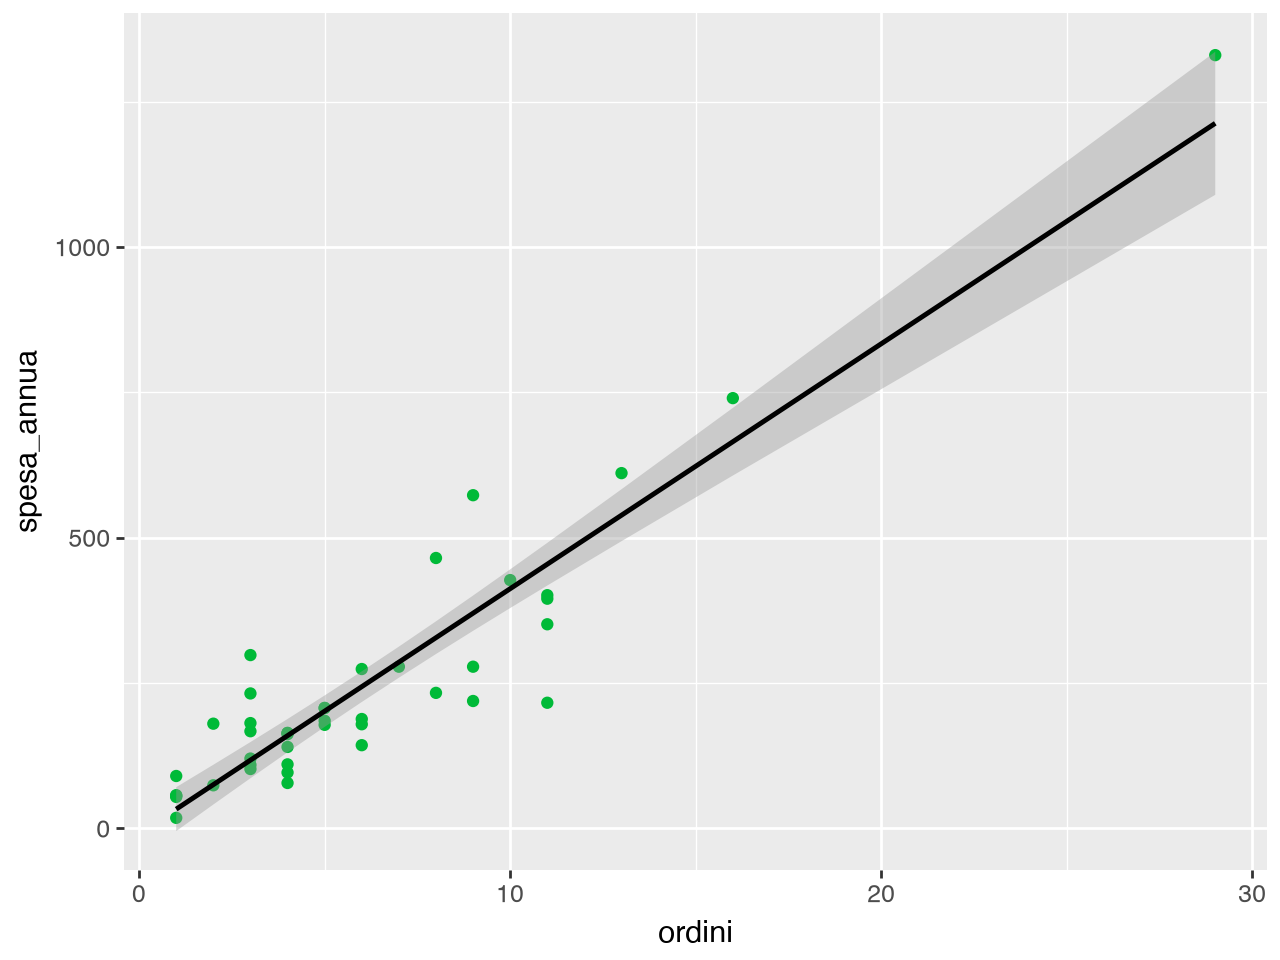

In [8]:
# solo i clienti del negozio
ggplot(clienti.filter(pl.col("canale") == "Negozio"), aes(x="ordini", y="spesa_annua")) + geom_point(color="#00BA38") + geom_smooth(method="lm")

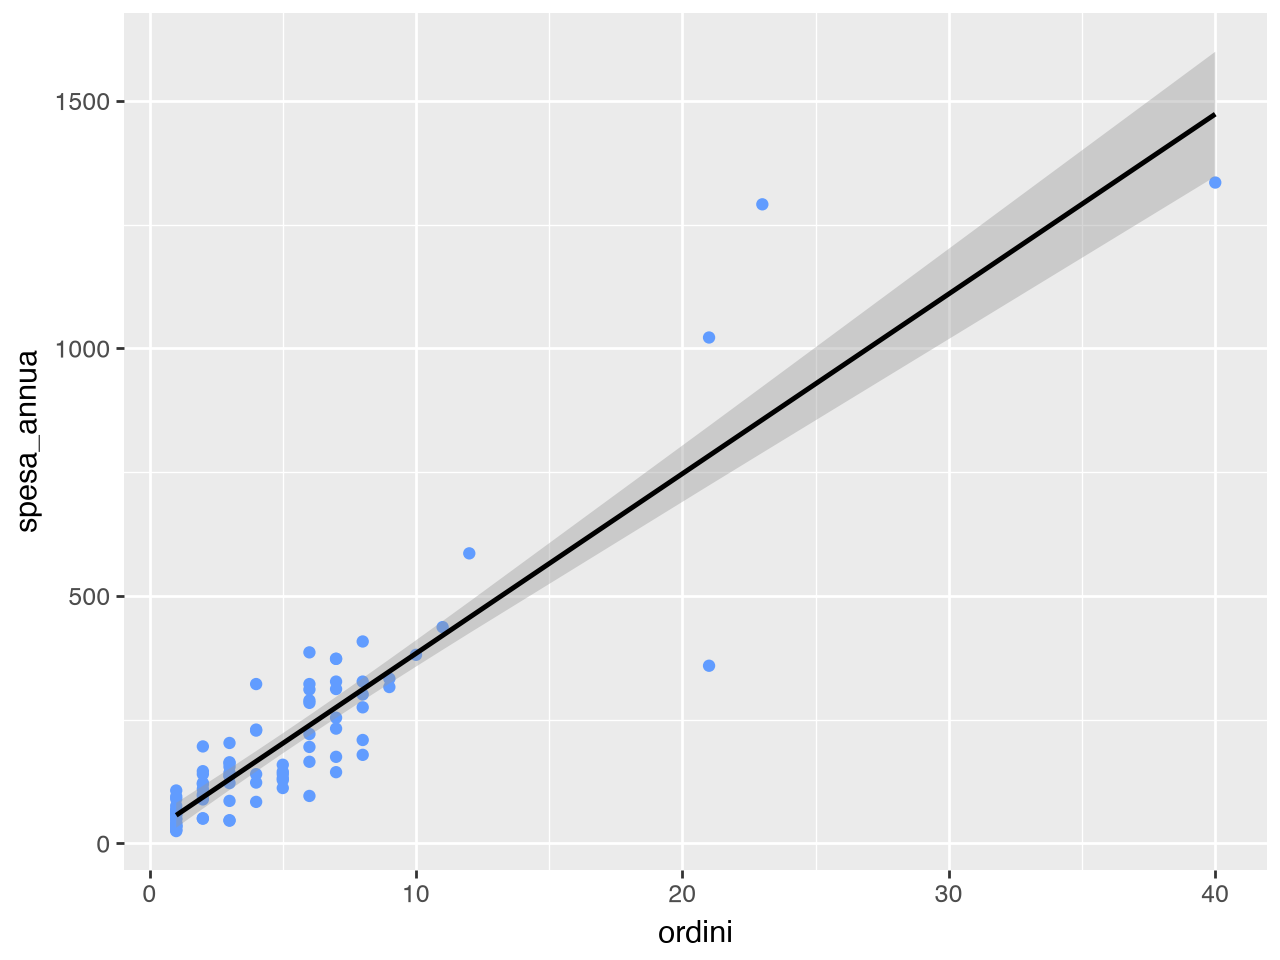

In [9]:
# solo i clienti del sito
ggplot(clienti.filter(pl.col("canale") == "Sito"), aes(x="ordini", y="spesa_annua")) + geom_point(color="#619CFF") + geom_smooth(method="lm")

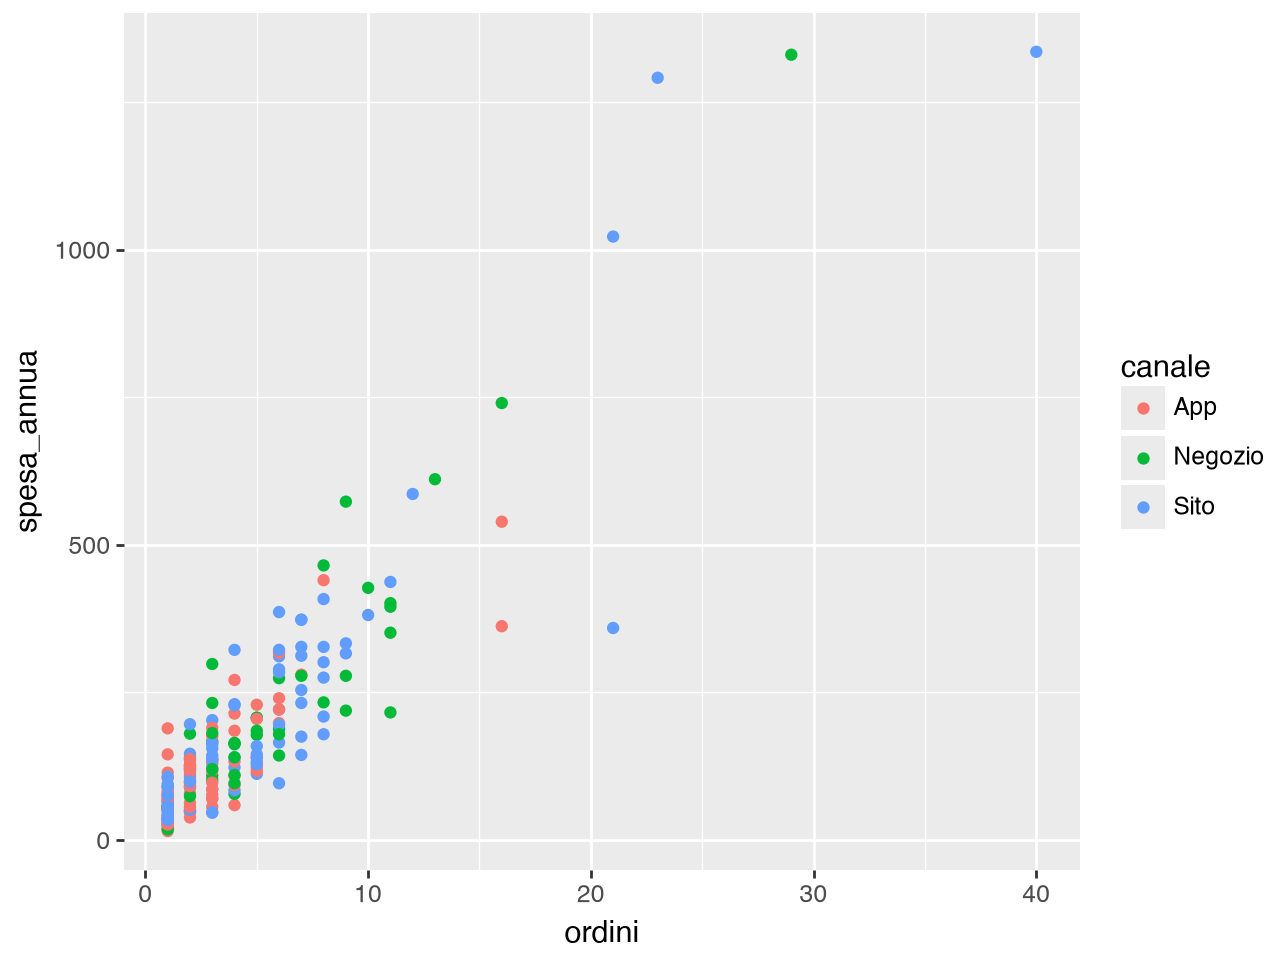

In [10]:
# tutti insieme: color="canale" colora i punti secondo la colonna canale (App rosso, Negozio verde, Sito blu)
ggplot(clienti, aes(x="ordini", y="spesa_annua", color="canale")) + geom_point()

### 2.4 A parità di numero di ordini, il canale conta ancora?

**Cosa mi chiede?** "A parità di ordini": anche `ordini` va nel modello, insieme a `canale`. y = `spesa_annua`, x = `canale` e `ordini`. Comando: `smf.ols`.

In [11]:
# canale[T.Negozio] p-value 0.55, canale[T.Sito] 0.75: sopra 0.05, a parità di ordini il canale non è più significativo
# ordini 36.8: a parità di canale, ogni ordine in più, in media 37 euro di spesa in più; p-value 0.000
# chi compra in negozio spende di più perché fa più ordini
modello2 = smf.ols("spesa_annua ~ canale + ordini", data=clienti).fit()
modello2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            spesa_annua   R-squared:                       0.831
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     321.9
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           1.88e-75
Time:                        22:37:46   Log-Likelihood:                -1162.0
No. Observations:                 200   AIC:                             2332.
Df Residuals:                     196   BIC:                             2345.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            14.0187     10.369      1.352      0.178      -6.431      34.468
canale[T.Negozio]     9.6763     16.215      0.597      0.551     -22.301      41.654
canale[T.Sito]        4.2308     13.333      0.317      0.751     -22.064      30.526
ordini               36.7845      1.230     29.904      0.000      34.359      39.210
==============================================================================
Omnibus:                       41.011   Durbin-Watson:                   2.005
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              475.618
Skew:                           0.175   Prob(JB):                    5.26e-104
Kurtosis:                      10.547   Cond. No.                         22.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### 2.5 Quanto spende in un anno un cliente con 5 ordini, se compra dall'app? E se compra in negozio?

**Cosa mi chiede?** "Quanto spende un cliente con...": una previsione, `predict` con il modello del punto 2.4. Gli diamo il valore di **ogni** x: `canale` (il testo, come nei dati) e `ordini`.

In [12]:
# app: 198 euro; negozio: 208. Quasi uguali: conta il numero di ordini
modello2.predict({"canale": ["App", "Negozio"], "ordini": [5, 5]})

0    197.941339
1    207.617622
dtype: float64